In [5]:
#1. Load libraries
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt 

In [37]:
df = pd.read_csv("Dataset for Data Analytics.csv")

In [38]:
df.head()

,OrderID,Date,CustomerID,Product,Quantity,UnitPrice,ShippingAddress,PaymentMethod,OrderStatus,TrackingNumber,ItemsInCart,CouponCode,ReferralSource,TotalPrice
0,ORD200000,2023-01-04,C72649,Monitor,5,570.62,928 Main St,Debit Card,Shipped,TRK37947903,7,SAVE10,Instagram,2853.10
1,ORD200001,2024-08-23,C75739,Phone,2,151.35,823 Main St,Online,Shipped,TRK91186779,3,SAVE10,Referral,302.70
2,ORD200002,2024-02-27,C81728,Tablet,5,550.68,512 Main St,Credit Card,Cancelled,TRK42903982,8,FREESHIP,Email,2753.40
3,ORD200003,2023-10-15,C33540,Chair,1,273.19,275 Main St,Debit Card,Returned,TRK62788070,5,SAVE10,Facebook,273.19
4,ORD200004,2025-05-08,C81840,Printer,4,626.01,668 Main St,Online,Delivered,TRK29241424,8,SAVE10,Email,2504.04


In [39]:
df.tail()

,OrderID,Date,CustomerID,Product,Quantity,UnitPrice,ShippingAddress,PaymentMethod,OrderStatus,TrackingNumber,ItemsInCart,CouponCode,ReferralSource,TotalPrice
1195,ORD201195,2024-06-20,C21126,Desk,1,107.04,392 Main St,Credit Card,Cancelled,TRK38009181,6,FREESHIP,Google,107.04
1196,ORD201196,2024-03-04,C20095,Monitor,2,662.53,778 Main St,Online,Cancelled,TRK69207593,5,NaN,Facebook,1325.06
1197,ORD201197,2023-07-13,C79674,Tablet,2,436.84,275 Main St,Online,Delivered,TRK88039356,2,FREESHIP,Instagram,873.68
1198,ORD201198,2024-08-22,C64753,Chair,4,262.52,509 Main St,Debit Card,Cancelled,TRK71683331,4,WINTER15,Instagram,1050.08
1199,ORD201199,2023-06-11,C57502,Tablet,4,560.58,201 Main St,Gift Card,Returned,TRK51116746,6,SAVE10,Referral,2242.32


In [40]:
df.shape

(1200, 14)

In [41]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   OrderID          1200 non-null   object 
 1   Date             1200 non-null   object 
 2   CustomerID       1200 non-null   object 
 3   Product          1200 non-null   object 
 4   Quantity         1200 non-null   int64  
 5   UnitPrice        1200 non-null   float64
 6   ShippingAddress  1200 non-null   object 
 7   PaymentMethod    1200 non-null   object 
 8   OrderStatus      1200 non-null   object 
 9   TrackingNumber   1200 non-null   object 
 10  ItemsInCart      1200 non-null   int64  
 11  CouponCode       891 non-null    object 
 12  ReferralSource   1200 non-null   object 
 13  TotalPrice       1200 non-null   float64
dtypes: float64(2), int64(2), object(10)
memory usage: 131.4+ KB


In [42]:
df.describe()

,Quantity,UnitPrice,ItemsInCart,TotalPrice
count,1200.000000,1200.000000,1200.000000,1200.000000
mean,2.945833,356.412750,5.485000,1053.968300
std,1.407557,197.177146,2.281983,819.856558
min,1.000000,11.390000,1.000000,11.390000
25%,2.000000,186.062500,4.000000,410.520000
50%,3.000000,364.210000,5.000000,823.615000
75%,4.000000,521.570000,7.000000,1578.475000
max,5.000000,699.930000,10.000000,3456.400000


In [43]:
# Count missing values in each column
missing_values = df.isnull().sum()
print("\nCount of missing values per column:")
print(missing_values)



Count of missing values per column:
OrderID              0
Date                 0
CustomerID           0
Product              0
Quantity             0
UnitPrice            0
ShippingAddress      0
PaymentMethod        0
OrderStatus          0
TrackingNumber       0
ItemsInCart          0
CouponCode         309
ReferralSource       0
TotalPrice           0
dtype: int64


In [44]:
# calculate the percentage of missing values
Percentage_missing_values = (missing_values / len(df)) * 100
print("\nPercentage of missing values:")
print(Percentage_missing_values)


Percentage of missing values:
OrderID             0.00
Date                0.00
CustomerID          0.00
Product             0.00
Quantity            0.00
UnitPrice           0.00
ShippingAddress     0.00
PaymentMethod       0.00
OrderStatus         0.00
TrackingNumber      0.00
ItemsInCart         0.00
CouponCode         25.75
ReferralSource      0.00
TotalPrice          0.00
dtype: float64


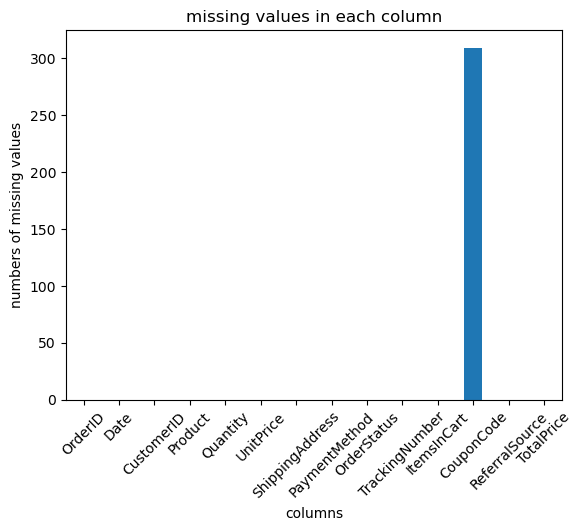

In [45]:
# visualising missing values
missing_values.plot(kind = "bar")
plt.title("missing values in each column")
plt.xlabel("columns")
plt.ylabel("numbers of missing values")
plt.xticks(rotation = 45)

plt.show()


In [46]:
# Handling missing values
df["CouponCode"] = df["CouponCode"].fillna("No Coupon")

In [47]:
df.duplicated().sum

<bound method Series.sum of 0       False
1       False
2       False
3       False
4       False
        ...  
1195    False
1196    False
1197    False
1198    False
1199    False
Length: 1200, dtype: bool>

In [48]:
df.isnull().sum()

OrderID            0
Date               0
CustomerID         0
Product            0
Quantity           0
UnitPrice          0
ShippingAddress    0
PaymentMethod      0
OrderStatus        0
TrackingNumber     0
ItemsInCart        0
CouponCode         0
ReferralSource     0
TotalPrice         0
dtype: int64

In [49]:
# convert date to date time
df['Date'] = pd.to_datetime(df['Date'], errors='coerce')

#check the data type
print(df['Date'].dtype)

df['Date'].isnull().sum()


datetime64[ns]


np.int64(0)

In [50]:
# Outlier detection and Winzorization

In [51]:
# Identify numerical columns
numeric_columns = [
    'Quantity',
    'UnitPrice',
    'ItemsInCart',
    'TotalPrice'
]

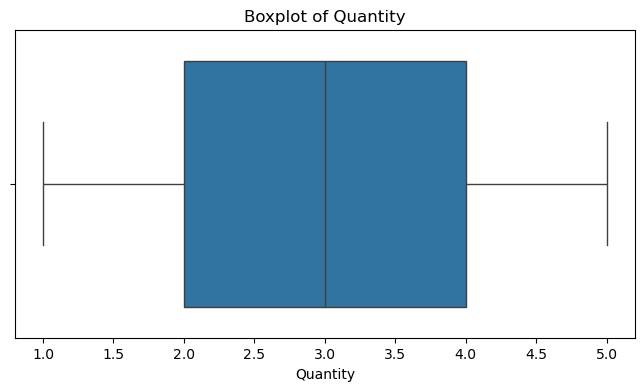

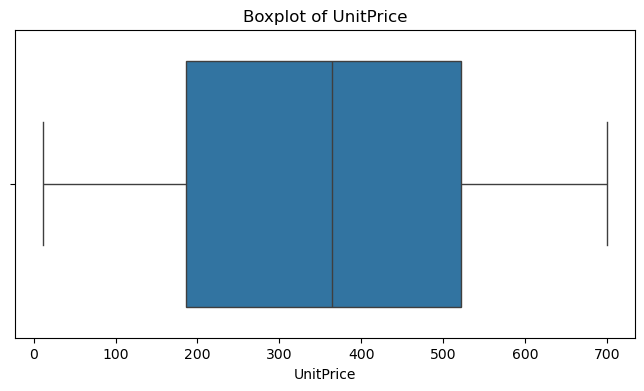

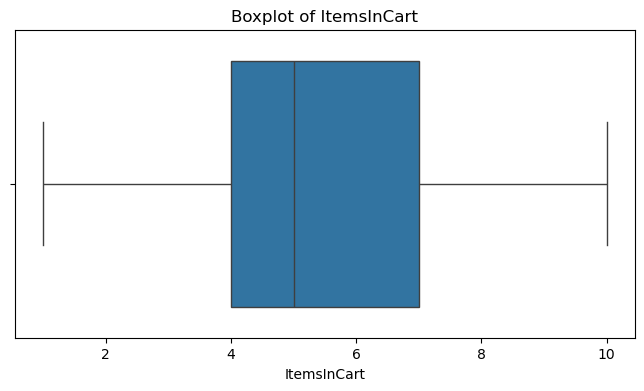

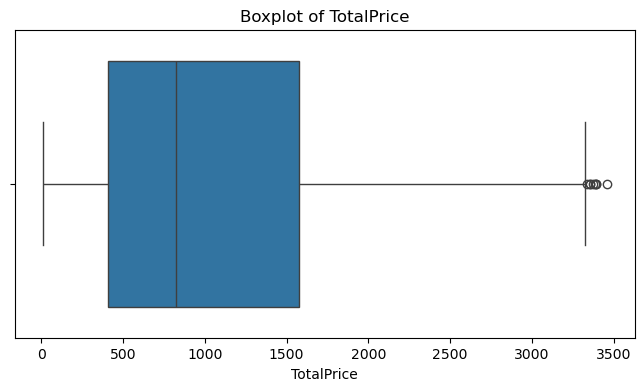

In [52]:
#Visualize numeric columns

for col in numeric_columns:
    plt.figure(figsize=(8, 4))
    sns.boxplot(x=df[col])
    plt.title(f'Boxplot of {col}')
    plt.show()

In [53]:
# Calculate the IQR boundaries
for col in numeric_columns:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - (1.5 * IQR)
    upper_bound = Q3 + (1.5 * IQR)

    print(f'\nColumn: {col}')
    print('Lower bound:', lower_bound)
    print('Upper bound:', upper_bound)

    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    print('Number of outliers:', len(outliers))


Column: Quantity
Lower bound: -1.0
Upper bound: 7.0
Number of outliers: 0

Column: UnitPrice
Lower bound: -317.1987499999999
Upper bound: 1024.8312499999997
Number of outliers: 0

Column: ItemsInCart
Lower bound: -0.5
Upper bound: 11.5
Number of outliers: 0

Column: TotalPrice
Lower bound: -1341.4125
Upper bound: 3330.4075
Number of outliers: 8


In [55]:
#Apply Winsorization

#preserve original numeric values
df_original = df.copy()

In [56]:
for col in numeric_columns:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - (1.5 * IQR)
    upper_bound = Q3 + (1.5 * IQR)

    df[col] = np.clip(
        df[col],
        lower_bound,
        upper_bound
    )

In [57]:
#check after Winsorization
for col in numeric_columns:

    print(f'\n{col}')

    print('Original maximum:',
          df_original[col].max())

    print('New maximum:',
          df[col].max())

    print('Original mean:',
          df_original[col].mean())

    print('New mean:',
          df[col].mean())


Quantity
Original maximum: 5
New maximum: 5
Original mean: 2.9458333333333333
New mean: 2.9458333333333333

UnitPrice
Original maximum: 699.93
New maximum: 699.93
Original mean: 356.41275
New mean: 356.41275

ItemsInCart
Original maximum: 10
New maximum: 10
Original mean: 5.485
New mean: 5.485

TotalPrice
Original maximum: 3456.4
New maximum: 3330.4075
Original mean: 1053.9683
New mean: 1053.6431833333334


In [58]:
df.shape

(1200, 14)

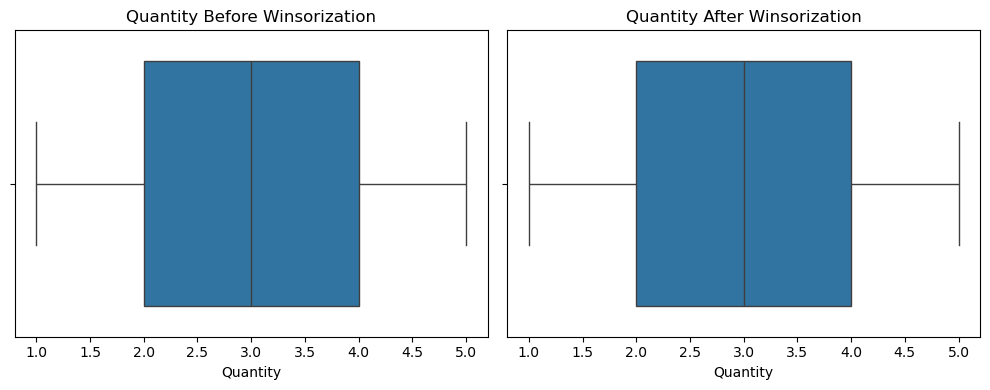

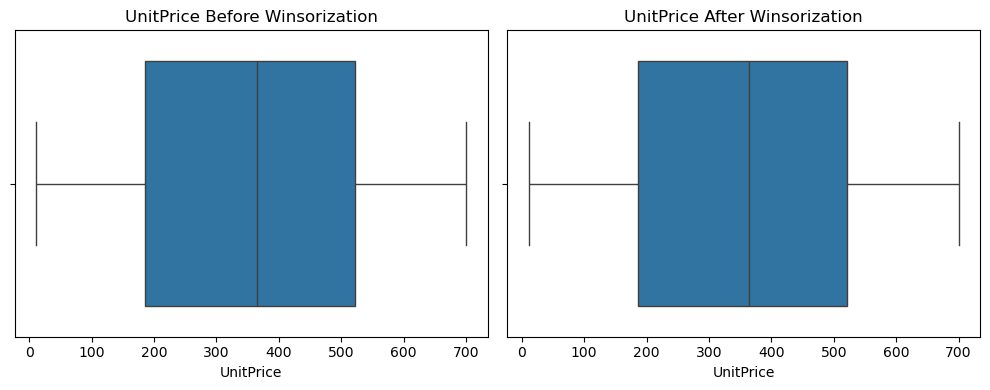

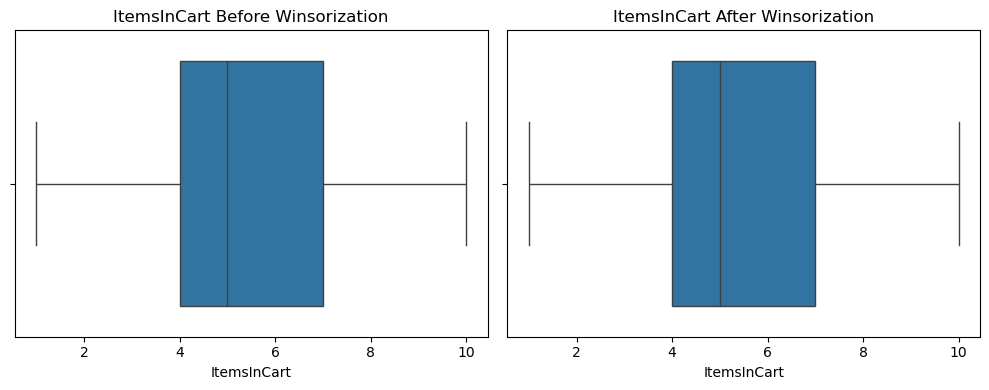

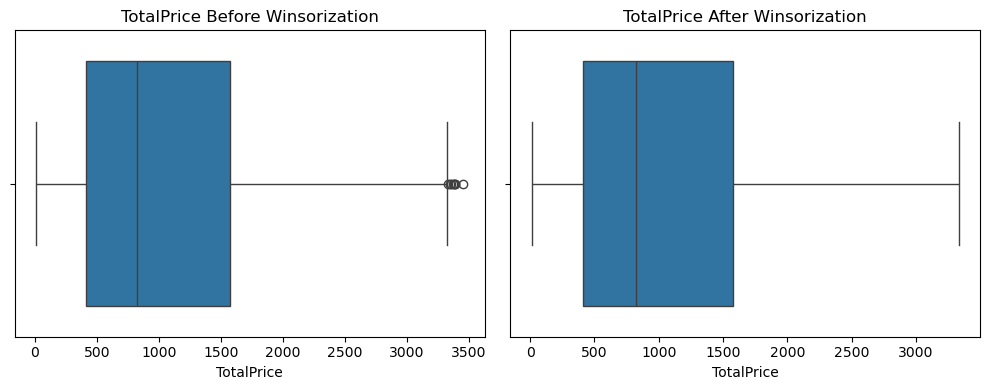

In [59]:
for col in numeric_columns:

    fig, axes = plt.subplots(1, 2, figsize=(10, 4))

    sns.boxplot(x=df_original[col], ax=axes[0])
    axes[0].set_title(f'{col} Before Winsorization')

    sns.boxplot(x=df[col], ax=axes[1])
    axes[1].set_title(f'{col} After Winsorization')

    plt.tight_layout()
    plt.show()

In [61]:
#Feature Engineering

#  Extract year
df['Year'] = df['Date'].dt.year

# Extract month
df['Month'] = df['Date'].dt.month

# Extract day of the week
df['DayOfWeek'] = df['Date'].dt.day_name()

# Feature 4: Calculate cart utilization
df['CartUtilization'] = (
    df['Quantity'] / df['ItemsInCart']
)

# Create order size categories
df['OrderSize'] = pd.cut(
    df['Quantity'],
    bins=[0, 2, 4, 5],
    labels=['Small', 'Medium', 'Large']
)

df.head()


,OrderID,Date,CustomerID,Product,Quantity,UnitPrice,ShippingAddress,PaymentMethod,OrderStatus,TrackingNumber,ItemsInCart,CouponCode,ReferralSource,TotalPrice,Year,Month,DayOfWeek,CartUtilization,OrderSize
0,ORD200000,2023-01-04,C72649,Monitor,5,570.62,928 Main St,Debit Card,Shipped,TRK37947903,7,SAVE10,Instagram,2853.10,2023,1,Wednesday,0.714286,Large
1,ORD200001,2024-08-23,C75739,Phone,2,151.35,823 Main St,Online,Shipped,TRK91186779,3,SAVE10,Referral,302.70,2024,8,Friday,0.666667,Small
2,ORD200002,2024-02-27,C81728,Tablet,5,550.68,512 Main St,Credit Card,Cancelled,TRK42903982,8,FREESHIP,Email,2753.40,2024,2,Tuesday,0.625000,Large
3,ORD200003,2023-10-15,C33540,Chair,1,273.19,275 Main St,Debit Card,Returned,TRK62788070,5,SAVE10,Facebook,273.19,2023,10,Sunday,0.200000,Small
4,ORD200004,2025-05-08,C81840,Printer,4,626.01,668 Main St,Online,Delivered,TRK29241424,8,SAVE10,Email,2504.04,2025,5,Thursday,0.500000,Medium


In [62]:
df.select_dtypes(
    include=['object', 'category']
).columns

Index(['OrderID', 'CustomerID', 'Product', 'ShippingAddress', 'PaymentMethod',
       'OrderStatus', 'TrackingNumber', 'CouponCode', 'ReferralSource',
       'DayOfWeek', 'OrderSize'],
      dtype='object')

In [64]:
#Check the number of unique categories
df.select_dtypes(
    include=['object', 'category']
).nunique()

OrderID            1200
CustomerID         1189
Product               7
ShippingAddress     655
PaymentMethod         5
OrderStatus           5
TrackingNumber     1200
CouponCode            4
ReferralSource        5
DayOfWeek             7
OrderSize             3
dtype: int64

In [65]:
categorical_columns = [
    'Product',
    'PaymentMethod',
    'OrderStatus',
    'ReferralSource',
    'DayOfWeek',
    'OrderSize'
]

In [66]:
df_encoded = pd.get_dummies(
    df,
    columns=categorical_columns,
    dtype=int
)

In [67]:
df_encoded.head()

,OrderID,Date,CustomerID,Quantity,UnitPrice,ShippingAddress,TrackingNumber,ItemsInCart,CouponCode,TotalPrice,...,DayOfWeek_Friday,DayOfWeek_Monday,DayOfWeek_Saturday,DayOfWeek_Sunday,DayOfWeek_Thursday,DayOfWeek_Tuesday,DayOfWeek_Wednesday,OrderSize_Small,OrderSize_Medium,OrderSize_Large
0,ORD200000,2023-01-04,C72649,5,570.62,928 Main St,TRK37947903,7,SAVE10,2853.10,...,0,0,0,0,0,0,1,0,0,1
1,ORD200001,2024-08-23,C75739,2,151.35,823 Main St,TRK91186779,3,SAVE10,302.70,...,1,0,0,0,0,0,0,1,0,0
2,ORD200002,2024-02-27,C81728,5,550.68,512 Main St,TRK42903982,8,FREESHIP,2753.40,...,0,0,0,0,0,1,0,0,0,1
3,ORD200003,2023-10-15,C33540,1,273.19,275 Main St,TRK62788070,5,SAVE10,273.19,...,0,0,0,1,0,0,0,1,0,0
4,ORD200004,2025-05-08,C81840,4,626.01,668 Main St,TRK29241424,8,SAVE10,2504.04,...,0,0,0,0,1,0,0,0,1,0


In [68]:
df_encoded.columns.tolist()

['OrderID',
 'Date',
 'CustomerID',
 'Quantity',
 'UnitPrice',
 'ShippingAddress',
 'TrackingNumber',
 'ItemsInCart',
 'CouponCode',
 'TotalPrice',
 'Year',
 'Month',
 'CartUtilization',
 'Product_Chair',
 'Product_Desk',
 'Product_Laptop',
 'Product_Monitor',
 'Product_Phone',
 'Product_Printer',
 'Product_Tablet',
 'PaymentMethod_Cash',
 'PaymentMethod_Credit Card',
 'PaymentMethod_Debit Card',
 'PaymentMethod_Gift Card',
 'PaymentMethod_Online',
 'OrderStatus_Cancelled',
 'OrderStatus_Delivered',
 'OrderStatus_Pending',
 'OrderStatus_Returned',
 'OrderStatus_Shipped',
 'ReferralSource_Email',
 'ReferralSource_Facebook',
 'ReferralSource_Google',
 'ReferralSource_Instagram',
 'ReferralSource_Referral',
 'DayOfWeek_Friday',
 'DayOfWeek_Monday',
 'DayOfWeek_Saturday',
 'DayOfWeek_Sunday',
 'DayOfWeek_Thursday',
 'DayOfWeek_Tuesday',
 'DayOfWeek_Wednesday',
 'OrderSize_Small',
 'OrderSize_Medium',
 'OrderSize_Large']

In [69]:
df_encoded.shape

(1200, 45)

In [70]:
df_encoded.isnull().sum()

OrderID                      0
Date                         0
CustomerID                   0
Quantity                     0
UnitPrice                    0
ShippingAddress              0
TrackingNumber               0
ItemsInCart                  0
CouponCode                   0
TotalPrice                   0
Year                         0
Month                        0
CartUtilization              0
Product_Chair                0
Product_Desk                 0
Product_Laptop               0
Product_Monitor              0
Product_Phone                0
Product_Printer              0
Product_Tablet               0
PaymentMethod_Cash           0
PaymentMethod_Credit Card    0
PaymentMethod_Debit Card     0
PaymentMethod_Gift Card      0
PaymentMethod_Online         0
OrderStatus_Cancelled        0
OrderStatus_Delivered        0
OrderStatus_Pending          0
OrderStatus_Returned         0
OrderStatus_Shipped          0
ReferralSource_Email         0
ReferralSource_Facebook      0
Referral

In [71]:
df_encoded.duplicated().sum()

np.int64(0)

In [72]:
df_encoded.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 45 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   OrderID                    1200 non-null   object        
 1   Date                       1200 non-null   datetime64[ns]
 2   CustomerID                 1200 non-null   object        
 3   Quantity                   1200 non-null   int64         
 4   UnitPrice                  1200 non-null   float64       
 5   ShippingAddress            1200 non-null   object        
 6   TrackingNumber             1200 non-null   object        
 7   ItemsInCart                1200 non-null   int64         
 8   CouponCode                 1200 non-null   object        
 9   TotalPrice                 1200 non-null   float64       
 10  Year                       1200 non-null   int32         
 11  Month                      1200 non-null   int32         
 12  CartUt

In [40]:
df_encoded.head(10)

,OrderID,Date,CustomerID,Quantity,UnitPrice,ShippingAddress,TrackingNumber,ItemsInCart,CouponCode,TotalPrice,...,DayOfWeek_Friday,DayOfWeek_Monday,DayOfWeek_Saturday,DayOfWeek_Sunday,DayOfWeek_Thursday,DayOfWeek_Tuesday,DayOfWeek_Wednesday,OrderSize_Small,OrderSize_Medium,OrderSize_Large
0,ORD200000,2023-01-04,C72649,5,570.62,928 Main St,TRK37947903,7,SAVE10,2853.10,...,0,0,0,0,0,0,1,0,0,1
1,ORD200001,2024-08-23,C75739,2,151.35,823 Main St,TRK91186779,3,SAVE10,302.70,...,1,0,0,0,0,0,0,1,0,0
2,ORD200002,2024-02-27,C81728,5,550.68,512 Main St,TRK42903982,8,FREESHIP,2753.40,...,0,0,0,0,0,1,0,0,0,1
3,ORD200003,2023-10-15,C33540,1,273.19,275 Main St,TRK62788070,5,SAVE10,273.19,...,0,0,0,1,0,0,0,1,0,0
4,ORD200004,2025-05-08,C81840,4,626.01,668 Main St,TRK29241424,8,SAVE10,2504.04,...,0,0,0,0,1,0,0,0,1,0
5,ORD200005,2023-10-23,C37249,2,245.86,934 Main St,TRK72976927,4,SAVE10,491.72,...,0,1,0,0,0,0,0,1,0,0
6,ORD200006,2025-06-17,C83492,1,664.42,986 Main St,TRK96417362,6,SAVE10,664.42,...,0,0,0,0,0,1,0,1,0,0
7,ORD200007,2023-05-12,C41460,5,149.55,706 Main St,TRK78809193,9,FREESHIP,747.75,...,1,0,0,0,0,0,0,0,0,1
8,ORD200008,2025-04-02,C26817,2,134.28,904 Main St,TRK61042692,2,Unknown,268.56,...,0,0,0,0,0,0,1,1,0,0
9,ORD200009,2023-11-21,C31946,4,509.38,102 Main St,TRK33478363,6,SAVE10,2037.52,...,0,0,0,0,0,1,0,0,1,0


In [74]:
df_encoded.to_excel(
    'Final_Cleaned_Dataset_for_Data_Analytics.xlsx',
    index=False
)